<a href="https://www.kaggle.com/code/mdemonbinabutaher/infectious-skin-disease?scriptVersionId=373972756" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

# **Import Library**

In [1]:
import os
import glob
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    roc_curve,
    auc,
    roc_auc_score
)

from sklearn.preprocessing import label_binarize

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


# **Dataset Path Exploration**

In [2]:
DATA_DIR = Path(
    "/kaggle/input/datasets/gupiii/infectious-skin-disease-dataset"
)

print("Dataset exists:", DATA_DIR.exists())

if DATA_DIR.exists():
    for root, dirs, files in os.walk(DATA_DIR):
        level = len(Path(root).relative_to(DATA_DIR).parts)

        if level <= 2:
            print(
                "  " * level,
                Path(root).name,
                "| Images:", len([
                    f for f in files
                    if f.lower().endswith(
                        (".jpg", ".jpeg", ".png", ".bmp")
                    )
                ])
            )

Dataset exists: True
 infectious-skin-disease-dataset | Images: 0
   Dataset_1 | Images: 0
     Chickenpox | Images: 100
     Measles | Images: 80
     Monkeypox | Images: 264
     Normal | Images: 215
   Dataset_2 | Images: 0
     Chickenpox | Images: 107
     Measles | Images: 91
     Monkeypox | Images: 279
     Normal | Images: 293
   Dataset_Gabungan | Images: 0
     Chickenpox | Images: 207
     Measles | Images: 171
     Monkeypox | Images: 543
     Normal | Images: 508


# **Automatically Find Class Folders**

In [3]:
IMAGE_EXTENSIONS = (
    ".jpg", ".jpeg", ".png", ".bmp"
)

def count_images(folder):
    return sum(
        1 for f in folder.rglob("*")
        if f.is_file() and f.suffix.lower() in IMAGE_EXTENSIONS
    )

candidates = []

for folder in [DATA_DIR] + list(DATA_DIR.rglob("*")):

    if not folder.is_dir():
        continue

    subfolders = [
        d for d in folder.iterdir()
        if d.is_dir()
    ]

    valid_classes = [
        d for d in subfolders
        if count_images(d) > 0
    ]

    if len(valid_classes) >= 2:
        candidates.append(
            (len(valid_classes), folder)
        )

if not candidates:
    raise ValueError(
        "Class folders not found. Check dataset structure."
    )

candidates.sort(
    key=lambda x: (x[0], count_images(x[1])),
    reverse=True
)

DATA_ROOT = candidates[0][1]

print("Selected Dataset Root:", DATA_ROOT)

Selected Dataset Root: /kaggle/input/datasets/gupiii/infectious-skin-disease-dataset/Dataset_Gabungan


# **Create Image DataFrame**

In [4]:
image_paths = []
labels = []

for class_dir in sorted(DATA_ROOT.iterdir()):

    if not class_dir.is_dir():
        continue

    for image_path in class_dir.rglob("*"):

        if (
            image_path.is_file()
            and image_path.suffix.lower() in IMAGE_EXTENSIONS
        ):

            image_paths.append(str(image_path))
            labels.append(class_dir.name)

df = pd.DataFrame({
    "image_path": image_paths,
    "label": labels
})

print("Total Images:", len(df))
print("Total Classes:", df["label"].nunique())

print(df.head())

print("\nClass Distribution:")
print(df["label"].value_counts())

Total Images: 1429
Total Classes: 4
                                          image_path       label
0  /kaggle/input/datasets/gupiii/infectious-skin-...  Chickenpox
1  /kaggle/input/datasets/gupiii/infectious-skin-...  Chickenpox
2  /kaggle/input/datasets/gupiii/infectious-skin-...  Chickenpox
3  /kaggle/input/datasets/gupiii/infectious-skin-...  Chickenpox
4  /kaggle/input/datasets/gupiii/infectious-skin-...  Chickenpox

Class Distribution:
label
Monkeypox     543
Normal        508
Chickenpox    207
Measles       171
Name: count, dtype: int64


# **Class Distribution Visualization**

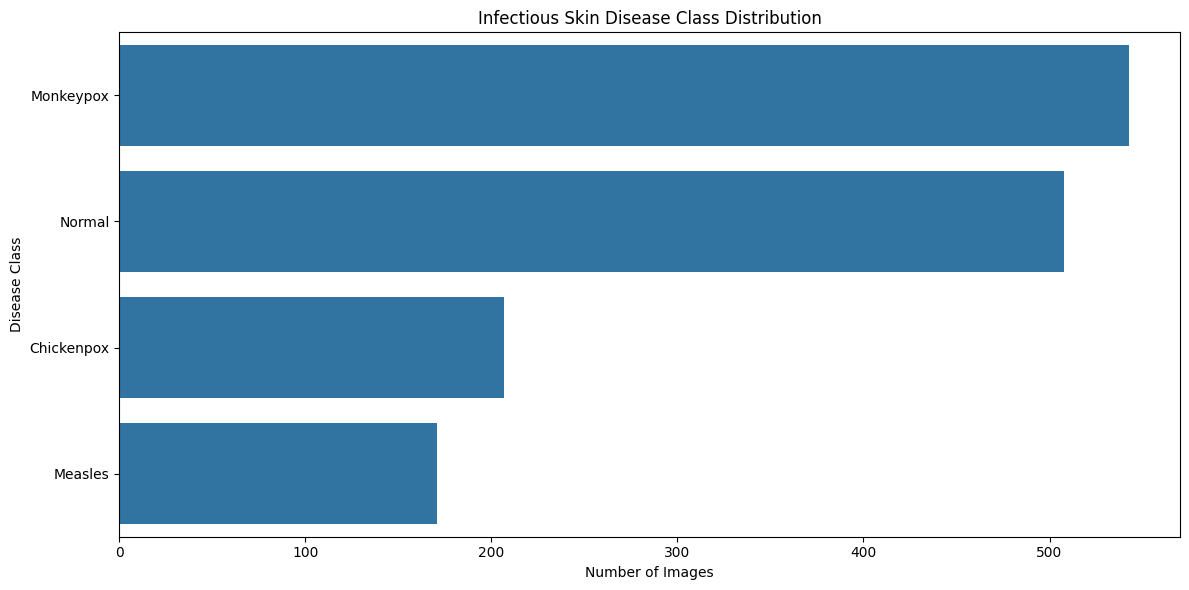

In [5]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    y="label",
    order=df["label"].value_counts().index
)

plt.title("Infectious Skin Disease Class Distribution")
plt.xlabel("Number of Images")
plt.ylabel("Disease Class")

plt.tight_layout()
plt.show()

# **Display Sample Images**

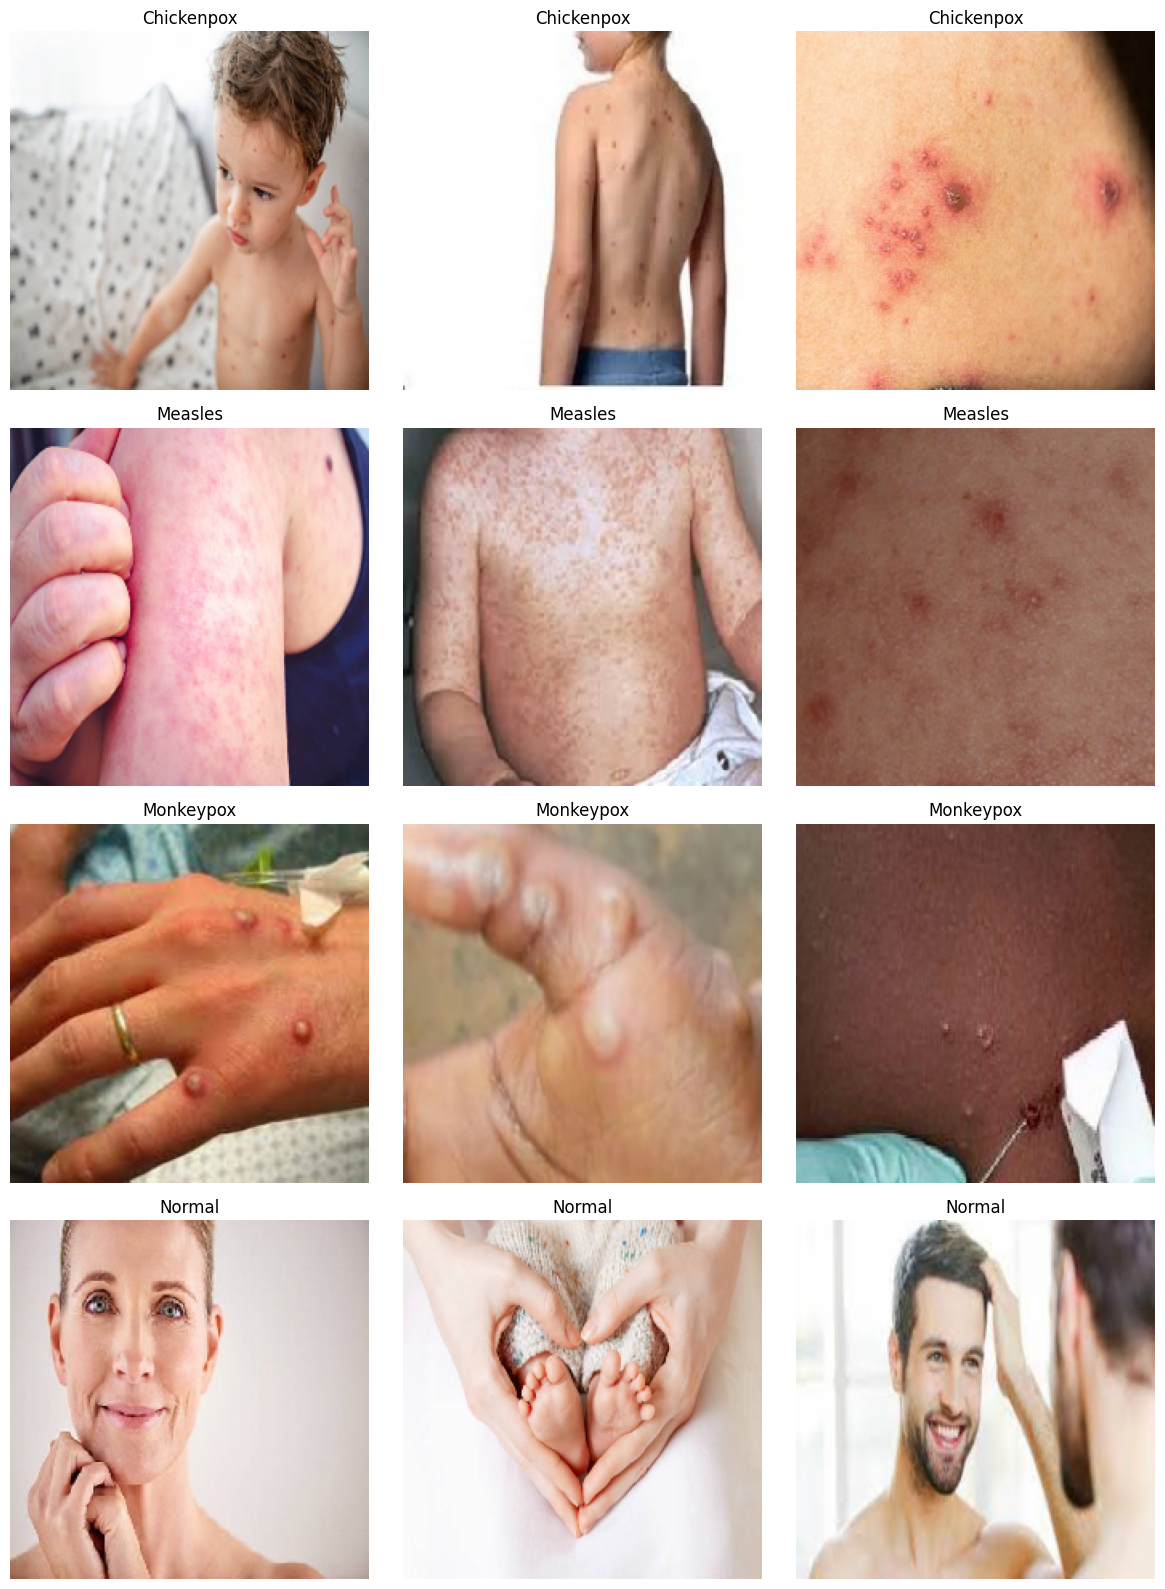

In [6]:
classes = sorted(df["label"].unique())

fig, axes = plt.subplots(
    len(classes),
    3,
    figsize=(12, 4 * len(classes))
)

for i, class_name in enumerate(classes):

    samples = df[
        df["label"] == class_name
    ].sample(
        min(3, len(df[df["label"] == class_name])),
        random_state=SEED
    )

    for j, (_, row) in enumerate(samples.iterrows()):

        img = tf.keras.utils.load_img(
            row["image_path"],
            target_size=(224, 224)
        )

        axes[i, j].imshow(img)
        axes[i, j].set_title(class_name)
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()

# **Train, Validation, Test Split**

In [7]:
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["label"],
    random_state=SEED
)

valid_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=SEED
)

print("Train:", len(train_df))
print("Validation:", len(valid_df))
print("Test:", len(test_df))

Train: 1000
Validation: 214
Test: 215


# **Label Encoding**

In [8]:
class_names = sorted(df["label"].unique())

class_to_index = {
    name: i for i, name in enumerate(class_names)
}

num_classes = len(class_names)

for data in [train_df, valid_df, test_df]:

    data["label_id"] = data["label"].map(
        class_to_index
    )

print("Classes:", class_names)
print("Number of Classes:", num_classes)

Classes: ['Chickenpox', 'Measles', 'Monkeypox', 'Normal']
Number of Classes: 4


# **Image Preprocessing**

In [9]:
IMG_SIZE = 224
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, label):

    image = tf.io.read_file(path)

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        (IMG_SIZE, IMG_SIZE)
    )

    image = tf.cast(image, tf.float32)

    label = tf.one_hot(
        label,
        depth=num_classes
    )

    return image, label


def create_dataset(dataframe, training=False):

    paths = dataframe["image_path"].values
    labels = dataframe["label_id"].values

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        dataset = dataset.shuffle(
            len(dataframe),
            seed=SEED
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)

    dataset = dataset.prefetch(AUTOTUNE)

    return dataset


train_ds = create_dataset(train_df, True)
valid_ds = create_dataset(valid_df)
test_ds = create_dataset(test_df)

print("Dataset Ready!")

Dataset Ready!


# **Data Augmentation**

In [10]:
data_augmentation = tf.keras.Sequential([

    tf.keras.layers.RandomFlip("horizontal"),

    tf.keras.layers.RandomRotation(0.10),

    tf.keras.layers.RandomZoom(0.10),

    tf.keras.layers.RandomContrast(0.10),

], name="data_augmentation")

# **EfficientNetB0 Transfer Learning**

In [11]:
base_model = tf.keras.applications.EfficientNetB0(

    weights="imagenet",

    include_top=False,

    input_shape=(224, 224, 3)
)

base_model.trainable = False

inputs = tf.keras.Input(
    shape=(224, 224, 3)
)

x = data_augmentation(inputs)

# EfficientNetB0 includes input rescaling internally.
x = base_model(x, training=False)

x = tf.keras.layers.GlobalAveragePooling2D()(x)

x = tf.keras.layers.BatchNormalization()(x)

x = tf.keras.layers.Dropout(0.4)(x)

x = tf.keras.layers.Dense(
    256,
    activation="relu"
)(x)

x = tf.keras.layers.Dropout(0.3)(x)

outputs = tf.keras.layers.Dense(
    num_classes,
    activation="softmax"
)(x)

model = tf.keras.Model(
    inputs,
    outputs
)

model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,383,655 (16.72 MB)

 Trainable params: 331,524 (1.26 MB)

 Non-trainable params: 4,052,131 (15.46 MB)

# **Compile Model**

In [12]:
model.compile(

    optimizer=tf.keras.optimizers.Adamax(
        learning_rate=0.001
    ),

    loss="categorical_crossentropy",

    metrics=["accuracy"]
)

# **Class Weight Calculation**

In [13]:
class_weights_array = compute_class_weight(

    class_weight="balanced",

    classes=np.arange(num_classes),

    y=train_df["label_id"].values
)

class_weights = {
    i: weight
    for i, weight in enumerate(class_weights_array)
}

print(class_weights)

{0: np.float64(1.7241379310344827), 1: np.float64(2.0833333333333335), 2: np.float64(0.6578947368421053), 3: np.float64(0.704225352112676)}


# **Training Callbacks**

In [14]:
callbacks = [

    tf.keras.callbacks.ModelCheckpoint(

        "best_skin_disease.keras",

        monitor="val_loss",

        save_best_only=True,

        mode="min",

        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(

        monitor="val_loss",

        patience=5,

        restore_best_weights=True,

        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(

        monitor="val_loss",

        factor=0.3,

        patience=2,

        min_lr=1e-7,

        verbose=1
    )
]

# **Train Model (Phase 1)**

In [15]:
EPOCHS = 15

history = model.fit(

    train_ds,

    validation_data=valid_ds,

    epochs=EPOCHS,

    class_weight=class_weights,

    callbacks=callbacks
)

Epoch 1/15


E0000 00:00:1795613856.869494      22 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/functional_1_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 447ms/step - accuracy: 0.5812 - loss: 1.3972
Epoch 1: val_loss improved from None to 0.71587, saving model to best_skin_disease.keras

Epoch 1: finished saving model to best_skin_disease.keras
32/32 ━━━━━━━━━━━━━━━━━━━━ 38s 702ms/step - accuracy: 0.6610 - loss: 1.1368 - val_accuracy: 0.7430 - val_loss: 0.7159 - learning_rate: 0.0010
Epoch 2/15
31/32 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step - accuracy: 0.7592 - loss: 0.7087
Epoch 2: val_loss improved from 0.71587 to 0.59808, saving model to best_skin_disease.keras

Epoch 2: finished saving model to best_skin_disease.keras
32/32 ━━━━━━━━━━━━━━━━━━━━ 4s 115ms/step - accuracy: 0.7920 - loss: 0.6823 - val_accuracy: 0.7897 - val_loss: 0.5981 - learning_rate: 0.0010
Epoch 3/15
31/32 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step - accuracy: 0.8317 - loss: 0.5308
Epoch 3: val_loss improved from 0.59808 to 0.54687, saving model to best_skin_disease.keras

Epoch 3: finished saving model to best_skin_disease.keras
32/32 ━━━━━━━━━━━━━━━━

# **Fine Tuning (Phase 2)**

In [16]:
base_model.trainable = True

# Freeze all but the last 30 layers
for layer in base_model.layers[:-30]:

    layer.trainable = False

# Keep BatchNormalization layers frozen
for layer in base_model.layers:

    if isinstance(
        layer,
        tf.keras.layers.BatchNormalization
    ):
        layer.trainable = False

model.compile(

    optimizer=tf.keras.optimizers.Adamax(
        learning_rate=1e-5
    ),

    loss="categorical_crossentropy",

    metrics=["accuracy"]
)

fine_tune_history = model.fit(

    train_ds,

    validation_data=valid_ds,

    epochs=10,

    class_weight=class_weights,

    callbacks=callbacks
)

Epoch 1/10


E0000 00:00:1795613944.837499      22 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/functional_1_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


31/32 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - accuracy: 0.9069 - loss: 0.2976
Epoch 1: val_loss improved from 0.33283 to 0.33179, saving model to best_skin_disease.keras

Epoch 1: finished saving model to best_skin_disease.keras
32/32 ━━━━━━━━━━━━━━━━━━━━ 18s 212ms/step - accuracy: 0.8950 - loss: 0.2936 - val_accuracy: 0.8738 - val_loss: 0.3318 - learning_rate: 1.0000e-05
Epoch 2/10
31/32 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - accuracy: 0.9047 - loss: 0.2839
Epoch 2: val_loss improved from 0.33179 to 0.33107, saving model to best_skin_disease.keras

Epoch 2: finished saving model to best_skin_disease.keras
32/32 ━━━━━━━━━━━━━━━━━━━━ 4s 125ms/step - accuracy: 0.9130 - loss: 0.2497 - val_accuracy: 0.8738 - val_loss: 0.3311 - learning_rate: 1.0000e-05
Epoch 3/10
31/32 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - accuracy: 0.8968 - loss: 0.2759
Epoch 3: val_loss improved from 0.33107 to 0.33095, saving model to best_skin_disease.keras

Epoch 3: finished saving model to best_skin_disease.keras
32/32 ━━━━━━

# **Accuracy & Loss Visualization**

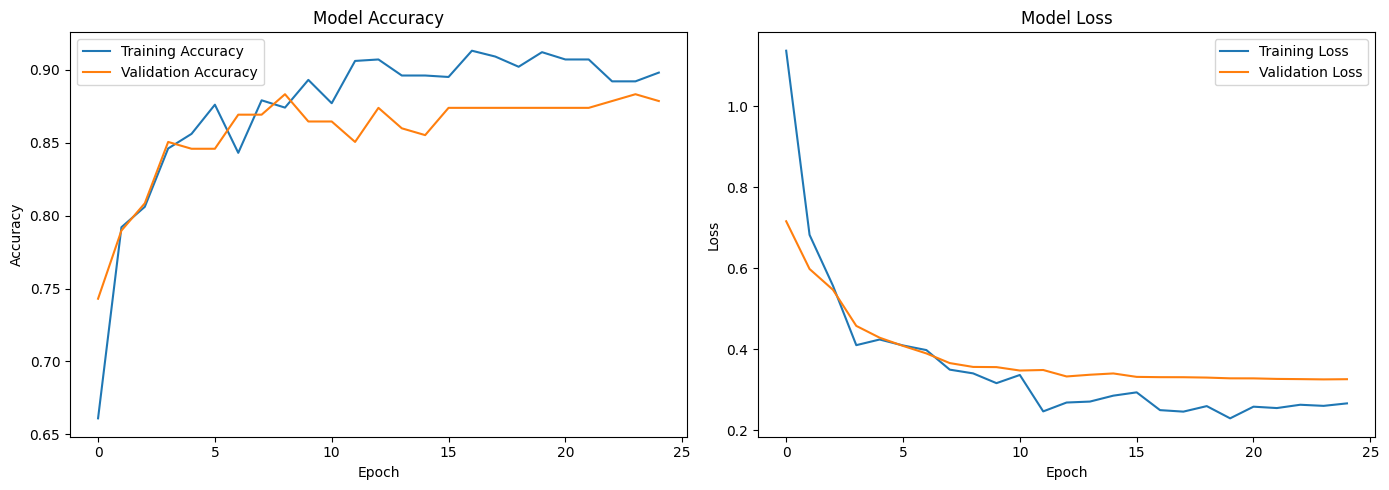

In [17]:
acc = (
    history.history["accuracy"]
    + fine_tune_history.history["accuracy"]
)

val_acc = (
    history.history["val_accuracy"]
    + fine_tune_history.history["val_accuracy"]
)

loss = (
    history.history["loss"]
    + fine_tune_history.history["loss"]
)

val_loss = (
    history.history["val_loss"]
    + fine_tune_history.history["val_loss"]
)

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)

plt.plot(acc, label="Training Accuracy")
plt.plot(val_acc, label="Validation Accuracy")

plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)

plt.plot(loss, label="Training Loss")
plt.plot(val_loss, label="Validation Loss")

plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

# **Load Best Model**

In [18]:
best_model = tf.keras.models.load_model(
    "best_skin_disease.keras"
)

print("Best model loaded successfully!")

Best model loaded successfully!


# **Test Evaluation**

In [19]:
test_loss, test_accuracy = best_model.evaluate(
    test_ds
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

7/7 ━━━━━━━━━━━━━━━━━━━━ 9s 636ms/step - accuracy: 0.9116 - loss: 0.2300
Test Loss: 0.23003888130187988
Test Accuracy: 0.9116278886795044


# **Classification Report**

In [20]:
y_true = test_df["label_id"].values

print("Actual Labels:", y_true.shape)

Actual Labels: (215,)


In [21]:
y_prob = best_model.predict(test_ds)

y_pred = np.argmax(y_prob, axis=1)

print("Predictions:", y_pred.shape)

7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 488ms/step
Predictions: (215,)


In [22]:
print(
    classification_report(

        y_true,

        y_pred,

        labels=np.arange(num_classes),

        target_names=class_names,

        zero_division=0
    )
)

              precision    recall  f1-score   support

  Chickenpox       0.76      0.94      0.84        31
     Measles       0.75      0.96      0.84        25
   Monkeypox       0.99      0.83      0.90        82
      Normal       0.99      0.97      0.98        77

    accuracy                           0.91       215
   macro avg       0.87      0.92      0.89       215
weighted avg       0.93      0.91      0.91       215



# **Confusion Matrix**

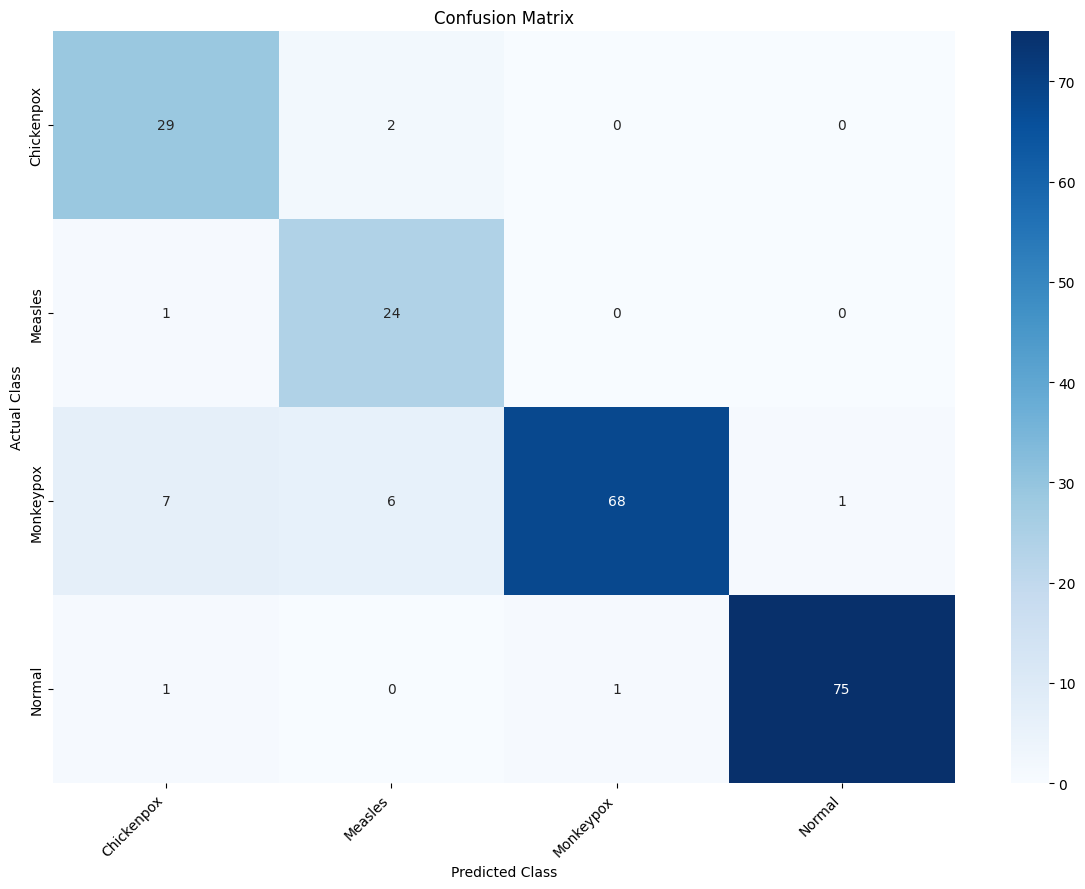

In [23]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(num_classes)
)

plt.figure(figsize=(12, 9))

sns.heatmap(

    cm,

    annot=True,

    fmt="d",

    cmap="Blues",

    xticklabels=class_names,

    yticklabels=class_names
)

plt.title("Confusion Matrix")

plt.xlabel("Predicted Class")

plt.ylabel("Actual Class")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()

plt.show()

# **Multiclass ROC Curve & AUC**

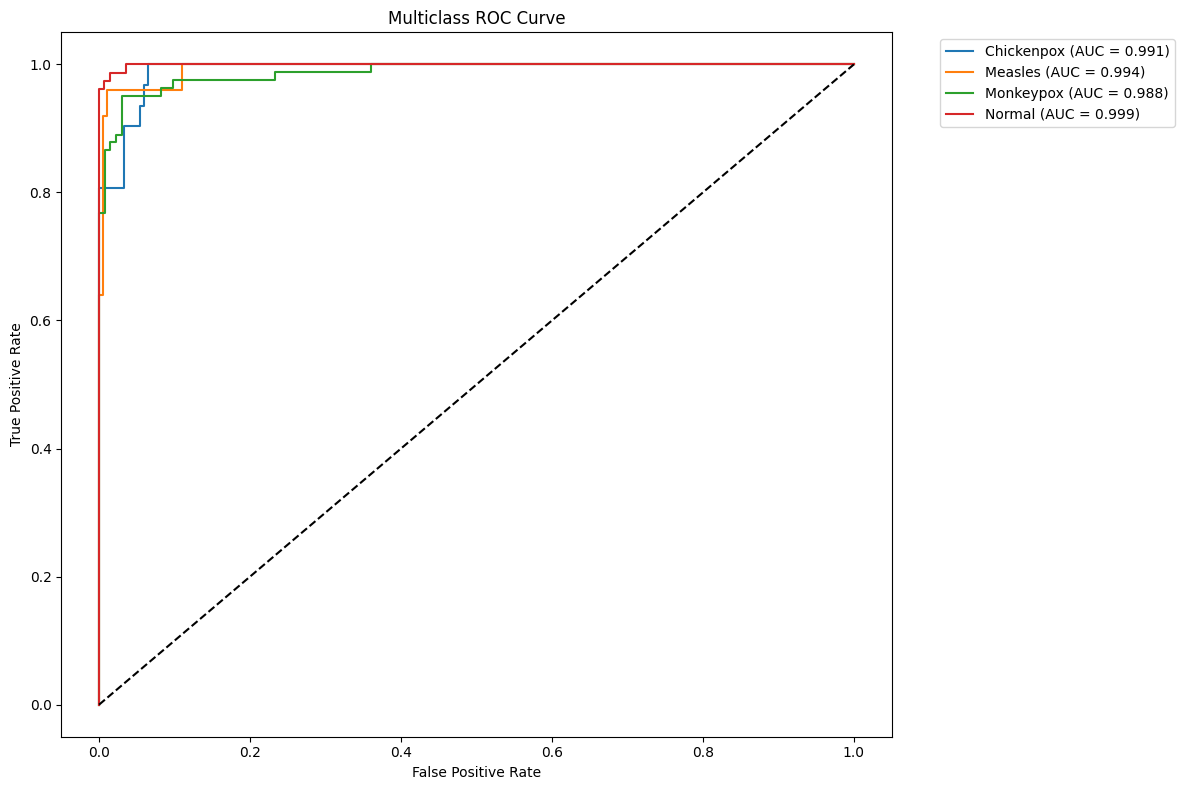

Macro ROC-AUC: 0.9928800115872788


In [24]:
y_true_binary = label_binarize(

    y_true,

    classes=np.arange(num_classes)
)

plt.figure(figsize=(12, 8))

for i, class_name in enumerate(class_names):

    fpr, tpr, _ = roc_curve(

        y_true_binary[:, i],

        y_prob[:, i]
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(

        fpr,

        tpr,

        label=f"{class_name} (AUC = {roc_auc:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    "k--"
)

plt.title("Multiclass ROC Curve")

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()

plt.show()

print(
    "Macro ROC-AUC:",
    roc_auc_score(
        y_true_binary,
        y_prob,
        average="macro",
        multi_class="ovr"
    )
)